# 08 · Image-only baseline — EfficientNet-B0

**In short:** an EfficientNet-B0 that already learned general image features on ImageNet
is **fine-tuned** on the training split to recognise the 11 classes from a leaf photo
alone. This is the image-only baseline the fusion model is later compared with.

- **Train** (11,477 images) is what the model learns from; after every pass (epoch) it is
  scored on **val**, and the best epoch is kept. Training stops early when val stops improving.
- **Test** is scored **once**, at the end: overall and per source (lab vs field).
- **PlantDoc** checks generalisation to photos from a different setting; the **unseen**
  tomato diseases show how confident the model is on diseases it never saw.
- Confidence is reported **uncalibrated** here (with its calibration error, ECE);
  temperature scaling and the referral threshold come in Sprint 4, using the saved val logits.

The finished model is saved as one file (`model.pt`) that the backend loads; training does
not need to be repeated unless the data or settings change. Progress is saved after every
epoch, so if Colab disconnects, re-running the notebook resumes where it stopped.

**Needs a GPU runtime (T4).**

In [1]:
from pathlib import Path
import sys

from google.colab import drive

drive.mount("/content/drive")

REPO_URL = "https://github.com/BilliartMuthoni/confidence-calibrated-crop-diagnosis.git"
REPO_DIR = Path("/content/drive/MyDrive/Sproutly-app")

if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}

ML_DIR = REPO_DIR / "ml"
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

import config

Mounted at /content/drive


In [2]:
# Keep the Drive copy of the repository in sync with GitHub.
!git -C {REPO_DIR} config core.fileMode false
!git -C {REPO_DIR} pull --ff-only
!git -C {REPO_DIR} status --short --branch

Already up to date.
Refresh index: 100% (96/96), done.
## main...origin/main
?? ml/notebooks/08b_image_plantvillage_only.ipynb


In [3]:
%pip install -q -r {ML_DIR}/requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 93.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.9 MB/s eta 0:00:00


## Settings

`RUN_NAME` and `TRAIN_SOURCES` select the experiment:
- main baseline: `"image_baseline"`, all three sources;
- PlantVillage-only (Sprint 2 extra run): `"image_plantvillage_only"`, `["plantvillage"]`.

Set `FRESH_START = True` to delete an earlier attempt of the same run instead of resuming it.

In [4]:
import shutil

import torch

from src import training

RUN_NAME = "image_plantvillage_only"
TRAIN_SOURCES = ["plantvillage"]

FRESH_START = False

SETTINGS = {
    "architecture": "efficientnet_b0 (ImageNet weights)",
    "image_size": 224,
    "batch_size": 64,
    "epochs": 15,
    "patience": 4,
    "learning_rate": 1e-3,
    "weight_decay": 1e-2,
    "seed": config.RANDOM_SEED,
    "train_sources": TRAIN_SOURCES,
}

assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU, then run again."
DEVICE = "cuda"
SETTINGS["gpu"] = torch.cuda.get_device_name(0)
SETTINGS["torch"] = torch.__version__

RUN_DIR = config.MODELS_DIR / RUN_NAME
if FRESH_START and RUN_DIR.exists():
    shutil.rmtree(RUN_DIR)
RUN_DIR.mkdir(parents=True, exist_ok=True)
training.seed_everything(config.RANDOM_SEED)
print("Run folder:", RUN_DIR, "| GPU:", SETTINGS["gpu"])

Run folder: /content/drive/MyDrive/CropDiseaseDiagnosis/models/image_plantvillage_only | GPU: Tesla T4


## Load the split

Train and val are limited to `TRAIN_SOURCES`; test keeps every source so results can be
compared per source.

In [5]:
import pandas as pd

splits = {name: pd.read_csv(config.SPLITS_DIR / f"{name}.csv") for name in ["train", "val", "test", "ood_test", "unseen_test"]}
for name in ["train", "val"]:
    splits[name] = splits[name][splits[name]["source"].isin(TRAIN_SOURCES)]

CLASSES = list(config.PLANTVILLAGE_CLASSES)
assert set(splits["train"]["class"]) == set(CLASSES), "Every class must have training images"
display(pd.DataFrame({name: rows["source"].value_counts() for name, rows in splits.items()}).fillna(0).astype(int))

,train,val,test,ood_test,unseen_test
source,,,,,
fieldplant,0,0,146,0,0
plantdoc,0,0,0,953,371
plantvillage,8863,1876,1878,0,0
tanzania,0,0,417,0,0


## Copy the images to local disk

One-off copy from Drive to Colab's fast local disk, shrinking each image so its shorter side
is 256 pixels. About 10 minutes the first time; instant if the runtime still has the copy.

In [6]:
from pathlib import Path

from src.data import image_dataset

LOCAL_ROOT = Path("/content/image_cache")
all_paths = sorted(set(pd.concat(splits.values())["path"]))
cached = image_dataset.cache_images(all_paths, config.RAW_DATA_DIR, LOCAL_ROOT)
assert cached == len(all_paths), f"Only {cached} of {len(all_paths)} images cached"
print("Cached", cached, "images in", LOCAL_ROOT)

Caching images:   0%|          | 0/14504 [00:00<?, ?it/s]

Cached 14504 images in /content/image_cache


In [7]:
from torch.utils.data import DataLoader

size = SETTINGS["image_size"]
datasets = {
    name: image_dataset.SplitDataset(
        rows, LOCAL_ROOT, CLASSES,
        image_dataset.train_transform(size) if name == "train" else image_dataset.eval_transform(size),
    )
    for name, rows in splits.items()
}
loaders = {
    name: DataLoader(ds, batch_size=SETTINGS["batch_size"], shuffle=name == "train", drop_last=name == "train",
                     num_workers=2, pin_memory=True, persistent_workers=True)
    for name, ds in datasets.items()
}
print({name: len(ds) for name, ds in datasets.items()})

{'train': 8863, 'val': 1876, 'test': 2441, 'ood_test': 953, 'unseen_test': 371}


## Train

Each line is one epoch. Expect roughly 1–3 minutes per epoch on a T4.

In [8]:
training.save_json(SETTINGS, RUN_DIR / "settings.json")
model = training.build_model(len(CLASSES))
history = training.fit(model, loaders["train"], loaders["val"], RUN_DIR, SETTINGS, DEVICE)
display(history.round(4))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 114MB/s]


Training:   0%|          | 0/138 [00:00<?, ?it/s]

Predicting:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch 1/15: train loss 0.8657 | val loss 0.1185 | val acc 0.9531 | val macro-F1 0.9017  (best) | 1.2 min


...

Epoch 13/15: train loss 0.0056 | val loss 0.0283 | val acc 0.9925 | val macro-F1 0.9896 | 1.1 min


Training:   0%|          | 0/138 [00:00<?, ?it/s]

Predicting:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch 14/15: train loss 0.0040 | val loss 0.0282 | val acc 0.9931 | val macro-F1 0.9908 | 1.1 min
Stopping early: no improvement for 4 epochs.


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_ece,minutes
0,1,0.8657,0.1185,0.9531,0.9017,0.0130,1.2125
1,2,0.1388,0.1045,0.9744,0.9685,0.0145,1.0837
2,3,0.0925,0.1015,0.9574,0.9475,0.0127,1.0974
3,4,0.0723,0.0550,0.9829,0.9766,0.0044,1.0757
4,5,0.0459,0.0601,0.9824,0.9722,0.0080,1.1082
5,6,0.0310,0.0368,0.9893,0.9852,0.0061,1.0948
6,7,0.0365,0.0560,0.9835,0.9805,0.0075,1.0898
7,8,0.0212,0.0419,0.9883,0.9862,0.0066,1.0719
8,9,0.0202,0.0292,0.9931,0.9907,0.0052,1.1063
9,10,0.0113,0.0285,0.9936,0.9918,0.0052,1.0764


## Training curves

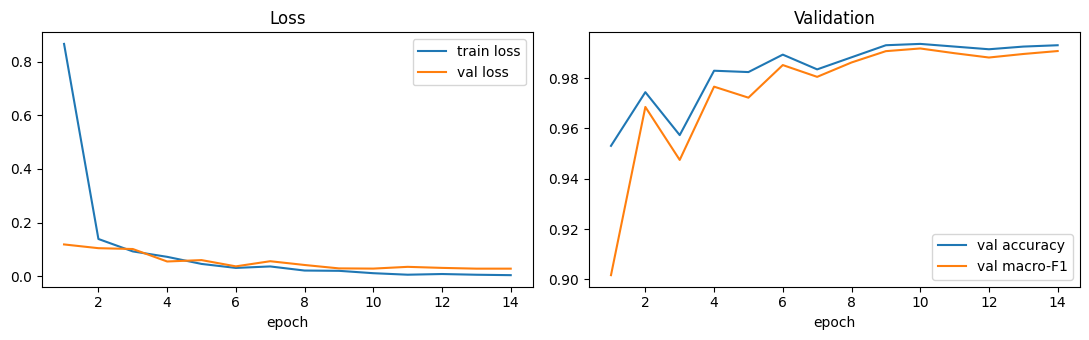

In [9]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(history["epoch"], history["train_loss"], label="train loss")
ax1.plot(history["epoch"], history["val_loss"], label="val loss")
ax1.set_xlabel("epoch"); ax1.legend(); ax1.set_title("Loss")
ax2.plot(history["epoch"], history["val_accuracy"], label="val accuracy")
ax2.plot(history["epoch"], history["val_macro_f1"], label="val macro-F1")
ax2.set_xlabel("epoch"); ax2.legend(); ax2.set_title("Validation")
plt.tight_layout()
plt.savefig(RUN_DIR / "training_curves.png", dpi=150)
plt.show()

## Evaluate the best epoch

Scores val, test (overall and per source) and PlantDoc. Predictions and raw scores (logits)
are saved for calibration in Sprint 4.

In [10]:
import numpy as np

from src import metrics

model.load_state_dict(torch.load(RUN_DIR / "best.pt", map_location=DEVICE))
model.to(DEVICE)
RESULTS_DIR = RUN_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

outputs, rows = {}, []
for name in ["val", "test", "ood_test", "unseen_test"]:
    logits, labels = training.predict(model, loaders[name], DEVICE)
    outputs[name] = training.save_predictions(splits[name], logits, CLASSES, RESULTS_DIR / f"{name}_predictions.csv")
    if name == "unseen_test":
        continue
    rows.append({"set": name, **metrics.summarise(logits, labels, len(CLASSES))})
    if name == "test":
        for source in sorted(splits["test"]["source"].unique()):
            mask = (splits["test"]["source"] == source).to_numpy()
            rows.append({"set": f"test: {source}", **metrics.summarise(logits[mask], labels[mask], len(CLASSES))})

results = pd.DataFrame(rows).set_index("set")
display(results.round(4))
results.to_csv(RESULTS_DIR / "metrics.csv")

unseen = outputs["unseen_test"]["confidence"]
print(f"Unseen tomato diseases ({len(unseen)} images): mean confidence {unseen.mean():.3f}, "
      f"{(unseen >= 0.9).mean():.1%} predicted with confidence >= 0.90")

Predicting:   0%|          | 0/30 [00:00<?, ?it/s]

Predicting:   0%|          | 0/39 [00:00<?, ?it/s]

Predicting:   0%|          | 0/15 [00:00<?, ?it/s]

Predicting:   0%|          | 0/6 [00:00<?, ?it/s]

,images,accuracy,macro_f1,ece,nll,mean_confidence
set,,,,,,
val,1876,0.9936,0.9918,0.0052,0.0285,0.9950
test,2441,0.8365,0.8297,0.1007,0.6160,0.9344
test: fieldplant,146,0.5068,0.6181,0.3229,2.0467,0.8112
test: plantvillage,1878,0.9952,0.9946,0.0033,0.0098,0.9950
test: tanzania,417,0.2374,0.3614,0.4837,2.8448,0.7046
ood_test,953,0.2938,0.2585,0.4754,3.4373,0.7691


Unseen tomato diseases (371 images): mean confidence 0.693, 26.1% predicted with confidence >= 0.90


## Per-class results and confusion matrix (test)

,precision,recall,f1-score,support
Maize Cercospora leaf spot Gray leaf spot,0.936,0.946,0.941,93.000
Maize Common rust,0.983,1.000,0.992,176.000
Maize Northern Leaf Blight,0.961,0.993,0.977,150.000
Maize healthy,0.584,0.990,0.734,201.000
Tomato Bacterial spot,0.971,1.000,0.985,304.000
Tomato Early blight,0.639,0.975,0.772,160.000
Tomato Late blight,0.707,0.917,0.798,339.000
Tomato healthy,0.996,0.850,0.917,273.000
Potato Early blight,0.953,0.652,0.774,279.000
Potato Late blight,0.975,0.660,0.787,297.000


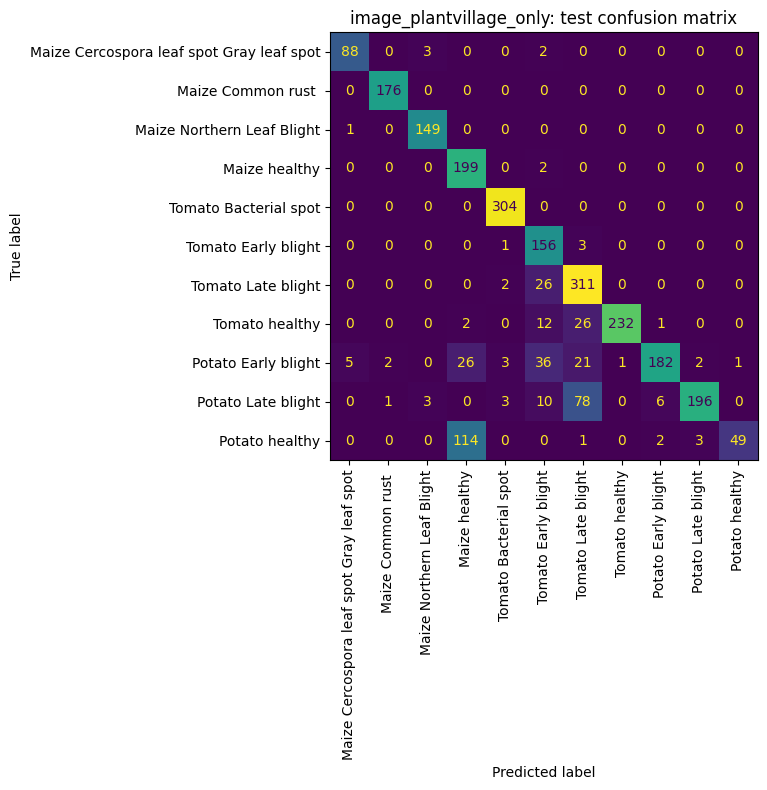

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

short = [c.replace("Corn_(maize)___", "Maize ").replace("___", " ").replace("_", " ") for c in CLASSES]
test_out = outputs["test"]
report = classification_report(test_out["class"], test_out["predicted"], labels=CLASSES, target_names=short,
                               digits=3, zero_division=0, output_dict=True)
report_table = pd.DataFrame(report).T.round(3)
display(report_table)
report_table.to_csv(RESULTS_DIR / "test_per_class.csv")

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(test_out["class"], test_out["predicted"], labels=CLASSES,
                                        display_labels=short, xticks_rotation=90, ax=ax, colorbar=False)
ax.set_title(f"{RUN_NAME}: test confusion matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "test_confusion_matrix.png", dpi=150)
plt.show()

## Export the model for the backend

`model.pt` holds the weights plus the class list, image size and normalisation, so the
backend needs nothing else to use it.

In [12]:
training.export(model.cpu(), CLASSES, SETTINGS["image_size"], image_dataset.MEAN, image_dataset.STD,
                RUN_DIR / "model.pt", SETTINGS)
print("Saved", RUN_DIR / "model.pt", f"({(RUN_DIR / 'model.pt').stat().st_size / 1e6:.1f} MB)")

Saved /content/drive/MyDrive/CropDiseaseDiagnosis/models/image_plantvillage_only/model.pt (16.4 MB)


## Make sure Drive has saved everything

Colab uploads files to Drive in the background; this waits until the upload has finished
(see DEF-01), then reconnects Drive for the push.

In [13]:
drive.flush_and_unmount()
drive.mount("/content/drive")
print("Drive synced and remounted.")

Mounted at /content/drive
Drive synced and remounted.


## Save to GitHub

Commits the changed notebook to a new branch and prints a link to open the pull
request (`main` is protected). Change the branch name if this cell has already been
run once. Save the notebook (Ctrl+S) before running this cell.

In [ ]:
from google.colab import userdata

from src import github_sync

print(github_sync.status(REPO_DIR))
print()
print(github_sync.push(
    REPO_DIR,
    branch=f"colab/{RUN_NAME.replace('_', '-')}",
    message=f"Train and evaluate {RUN_NAME}",
    token=userdata.get("GITHUB_TOKEN"),
    name="BilliartMuthoni",
    email=userdata.get("GIT_EMAIL"),
))